# Dataset de modelagem – Lead Time Portuário da soja exportada (ANTAQ 2019–2025)

**Grão:** 1 linha = 1 atracação com embarque de soja (NCM `1201`) em Longo Curso Exportação.

**Target:** `lead_time_h` = T1 + T2 + T3 + T4 = Data Chegada → Data Desatracação (= `TEstadia` da ANTAQ), em horas.

| | Definição | Coluna ANTAQ |
|---|---|---|
| T1 | Chegada → Atracação | `TEsperaAtracacao` |
| T2 | Atracação → Início Operação | `TEsperaInicioOp` |
| T3 | Início → Término Operação | `TOperacao` |
| T4 | Término Operação → Desatracação | `TEsperaDesatracacao` |

**Regra das features:** só entra como feature o que é conhecido **no momento da chegada do navio** (`Data Chegada`).
Datas de atracação/operação/desatracação, T1–T4 e paralisações da própria atracação ficam de fora (vazamento).

**Fonte:** https://aquarela.antaq.gov.br (Estatístico Aquaviário → Base de Dados). Por ano são usados 3 zips:
`{ano}Atracacao.zip`, `{ano}Carga.zip` e `{ano}TemposAtracacao.zip` (este traz também a Paralisação),
extraídos em `Tabelas_Fato_{ano}`.

O modelo Random Forest está em `Modelo_RandomForest.ipynb`, que lê o `dataset_modelo.parquet` gerado aqui.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

BASE = Path.cwd()                  # rodar o notebook a partir da pasta Data_Set
ANOS = list(range(2019, 2026))     # 2019 a 2025
NCM_SOJA = "1201"

ANOS = [ano for ano in ANOS if (BASE / f"Tabelas_Fato_{ano}").exists()]
print(f"Anos encontrados: {ANOS}")


def ler_antaq(caminho, **kwargs):
    return pd.read_csv(caminho, sep=";", dtype=str, encoding="utf-8-sig", **kwargs)


def ler_fato(tabela, **kwargs):
    ## Junta o mesmo arquivo de todos os anos em ANOS
    return pd.concat(
        [ler_antaq(BASE / f"Tabelas_Fato_{ano}" / f"{ano}{tabela}.txt", **kwargs) for ano in ANOS],
        ignore_index=True,
    )


def para_numero(serie):
    return pd.to_numeric(serie.str.replace(",", ".", regex=False), errors="coerce")


def para_data(serie):
    ## A ANTAQ usa dd/mm/aaaa hh:mm:ss, mas a Paralisação de alguns anos vem em ISO (aaaa-mm-dd hh:mm:ss.ffffff)
    datas = pd.to_datetime(serie, format="%d/%m/%Y %H:%M:%S", errors="coerce")
    faltando = datas.isna() & serie.notna()
    datas[faltando] = pd.to_datetime(serie[faltando], format="ISO8601", errors="coerce")
    return datas

Anos encontrados: [2019, 2020, 2021, 2022, 2023, 2024, 2025]


### Extraindo dados brutos

A tabela Carga tem ~2,2 milhões de linhas por ano. Para não estourar a memória, cada ano é lido, filtrado e descartado:

1 - [CDMercadoria] == "1201" (Soja)

2 - [Sentido] == "Embarcados"

3 - [Tipo Operação da Carga] == "Longo Curso Exportação"

Do mesmo ano também se guarda: tudo o que foi embarcado nas atracações de soja (para `pct_soja`) e os IDs das
atracações de granel sólido (para as features de congestionamento).

Obs.: a regra antiga era `FlagLongoCurso == 1` + destino ≠ Brasil. As atracações que só entram pela regra nova
vão para a aba `Validar_FlagLongoCurso` do Excel.

In [3]:
COLS_CARGA = ["IDCarga", "IDAtracacao", "Origem", "Destino", "CDMercadoria", "Tipo Operação da Carga",
              "Sentido", "FlagLongoCurso", "Natureza da Carga", "VLPesoCargaBruta"]

lista_soja, lista_embarques, lista_granel, etapas = [], [], [], []
for ano in ANOS:
    carga = ler_antaq(BASE / f"Tabelas_Fato_{ano}" / f"{ano}Carga.txt", usecols=COLS_CARGA)
    carga["VLPesoCargaBruta"] = para_numero(carga["VLPesoCargaBruta"])

    Df_Carga_v1 = carga[carga["CDMercadoria"] == NCM_SOJA]
    Df_Carga_v2 = Df_Carga_v1[Df_Carga_v1["Sentido"] == "Embarcados"]
    Df_Carga_v3 = Df_Carga_v2[Df_Carga_v2["Tipo Operação da Carga"] == "Longo Curso Exportação"]

    lista_soja.append(Df_Carga_v3)
    lista_embarques.append(carga[carga["IDAtracacao"].isin(Df_Carga_v3["IDAtracacao"])
                                 & (carga["Sentido"] == "Embarcados")])
    lista_granel.append(carga.loc[carga["Natureza da Carga"] == "Granel Sólido", "IDAtracacao"].drop_duplicates())
    etapas.append({"ano": ano, "1° bruto": len(carga), "2° soja": len(Df_Carga_v1), "3° embarcados": len(Df_Carga_v2),
                   "4° LC exportação": len(Df_Carga_v3), "atracações": Df_Carga_v3["IDAtracacao"].nunique()})
    del carga

Df_Soja = pd.concat(lista_soja, ignore_index=True)
Df_Embarques = pd.concat(lista_embarques, ignore_index=True)
ids_granel = pd.concat(lista_granel).unique()

## Resultado de filtro para cada etapa, por ano
pd.DataFrame(etapas).set_index("ano")

,1° bruto,2° soja,3° embarcados,4° LC exportação,atracações
ano,,,,,
2019,2018980,13521,9783,6267,1265
2020,2111365,15312,10976,6922,1371
2021,2348365,15689,11345,7240,1465
2022,2280017,14398,10624,6793,1325
2023,2200645,18153,13019,8527,1738
2024,2439642,19391,13215,8071,1616
2025,2467854,23314,15357,8658,1783


In [4]:
## Atracações que a regra antiga (FlagLongoCurso == 1) deixava de fora
ids_regra_antiga = set(Df_Soja.loc[Df_Soja["FlagLongoCurso"] == "1", "IDAtracacao"])
Df_Divergentes = Df_Soja[~Df_Soja["IDAtracacao"].isin(ids_regra_antiga)]
print(f"Atracações só na regra nova: {Df_Divergentes['IDAtracacao'].nunique()}")
print(Df_Divergentes["FlagLongoCurso"].value_counts(dropna=False))

Atracações só na regra nova: 197
FlagLongoCurso
0    255
Name: count, dtype: int64


In [5]:
Df_Atracacao_Bruto = ler_fato("Atracacao").drop_duplicates("IDAtracacao")
Df_Tempos_Bruto = ler_fato("TemposAtracacao").drop_duplicates("IDAtracacao")
Df_Paralisacao_Bruto = ler_fato("TemposAtracacaoParalisacao")
D_Destino = ler_antaq(BASE / "Tabelas Dimensões" / "Instalacao_Destino.txt")

COLS_DATA = {"Data Chegada": "dt_chegada", "Data Atracação": "dt_atracacao",
             "Data Início Operação": "dt_inicio_op", "Data Término Operação": "dt_termino_op",
             "Data Desatracação": "dt_desatracacao"}
for col, novo in COLS_DATA.items():
    Df_Atracacao_Bruto[novo] = para_data(Df_Atracacao_Bruto[col])

for col in Df_Tempos_Bruto.columns.drop("IDAtracacao"):
    Df_Tempos_Bruto[col] = para_numero(Df_Tempos_Bruto[col])

Df_Paralisacao_Bruto["DTInicio"] = para_data(Df_Paralisacao_Bruto["DTInicio"])
Df_Paralisacao_Bruto["DTTermino"] = para_data(Df_Paralisacao_Bruto["DTTermino"])

print(f"Atracação: {len(Df_Atracacao_Bruto)} | Tempos: {len(Df_Tempos_Bruto)} | "
      f"Paralisação: {len(Df_Paralisacao_Bruto)}")
print("Datas não convertidas:",
      {c: int(Df_Atracacao_Bruto[c].isna().sum()) for c in COLS_DATA.values()},
      int(Df_Paralisacao_Bruto["DTInicio"].isna().sum()))

Atracação: 637218 | Tempos: 637218 | Paralisação: 980761
Datas não convertidas: {'dt_chegada': 1097, 'dt_atracacao': 1097, 'dt_inicio_op': 34773, 'dt_termino_op': 34754, 'dt_desatracacao': 0} 0


### Features de carga (agregadas por atracação)

In [6]:
Df_Soja_Dest = Df_Soja.merge(D_Destino[["Destino", "País Destino", "Continente Destino"]], on="Destino", how="left")

Df_Feat_Carga = Df_Soja_Dest.groupby("IDAtracacao").agg(
    peso_soja_t=("VLPesoCargaBruta", "sum"),
    n_lotes=("IDCarga", "count"),
    n_destinos=("Destino", "nunique"),
    flag_destino_hub=("País Destino", lambda s: int((s == "SINGAPURA").any())),
)

## Continente que recebe a maior tonelagem da atracação
continente = (Df_Soja_Dest.groupby(["IDAtracacao", "Continente Destino"])["VLPesoCargaBruta"].sum()
              .reset_index().sort_values("VLPesoCargaBruta", ascending=False)
              .drop_duplicates("IDAtracacao").set_index("IDAtracacao")["Continente Destino"])
Df_Feat_Carga["continente_destino"] = continente

## Tudo que foi embarcado nessas atracações (soja + outras mercadorias)
Df_Feat_Carga = Df_Feat_Carga.join(Df_Embarques.groupby("IDAtracacao").agg(
    peso_total_embarcado_t=("VLPesoCargaBruta", "sum"),
    n_mercadorias=("CDMercadoria", "nunique"),
))
Df_Feat_Carga["pct_soja"] = Df_Feat_Carga["peso_soja_t"] / Df_Feat_Carga["peso_total_embarcado_t"]
Df_Feat_Carga = Df_Feat_Carga.reset_index()
Df_Feat_Carga.describe()

,peso_soja_t,n_lotes,n_destinos,flag_destino_hub,peso_total_embarcado_t,n_mercadorias,pct_soja
count,10563.000000,10563.000000,10563.000000,10563.000000,10563.000000,10563.000000,1.056300e+04
mean,59270.387839,4.968096,1.024804,0.078955,59838.885959,1.041087,9.893403e-01
std,16531.202554,4.643515,0.159144,0.269681,15691.078175,0.211434,8.916132e-02
min,0.010000,1.000000,1.000000,0.000000,13.315000,1.000000,2.282070e-07
25%,56700.002500,1.000000,1.000000,0.000000,57000.000000,1.000000,1.000000e+00
50%,65915.033000,4.000000,1.000000,0.000000,65957.229000,1.000000,1.000000e+00
75%,69295.720000,7.000000,1.000000,0.000000,69297.422500,1.000000,1.000000e+00
max,160000.000000,48.000000,3.000000,1.000000,160000.000000,4.000000,1.000000e+00


### Tratamento -> Atracação + Target

1 - Filtrar atracações com soja exportada

2 - Juntar `TemposAtracacao` (T1..T4 e TEstadia)

3 - Remover TE inválido: a ANTAQ grava o texto "Valor Discrepante" nos tempos que considera inconsistentes (o critério não é descrito na documentação); na conversão numérica esse texto vira nulo

4 - Janela de chegada: de 01/01 do primeiro ano até 90 dias antes da última desatracação da base.
Navios que chegaram no fim de 2025 e ainda não desatracaram não estão na base; sem esse corte, o fim do período
ficaria só com as estadias curtas (viés de censura). 90 dias é uma margem conservadora: quase o dobro do percentil 99 do TE da base final (≈ 47 dias).

In [7]:
COLS_ATRAC = ["IDAtracacao", "Porto Atracação", "Complexo Portuário", "Tipo da Autoridade Portuária",
              "Região Geográfica", "SGUF", "Nº do IMO"] + list(COLS_DATA.values())

Df_Atracacao_v1 = Df_Atracacao_Bruto.loc[Df_Atracacao_Bruto["IDAtracacao"].isin(Df_Soja["IDAtracacao"]), COLS_ATRAC]
Df_Atracacao_v2 = Df_Atracacao_v1.merge(
    Df_Tempos_Bruto.rename(columns={"TEsperaAtracacao": "t1_espera_atracacao_h",
                                    "TEsperaInicioOp": "t2_espera_inicio_op_h",
                                    "TOperacao": "t3_operacao_h",
                                    "TEsperaDesatracacao": "t4_espera_desatracacao_h",
                                    "TEstadia": "lead_time_h"})
    [["IDAtracacao", "t1_espera_atracacao_h", "t2_espera_inicio_op_h", "t3_operacao_h",
      "t4_espera_desatracacao_h", "lead_time_h"]],
    on="IDAtracacao", how="left")
Df_Atracacao_v3 = Df_Atracacao_v2[Df_Atracacao_v2["lead_time_h"].notna()]

INICIO_JANELA = pd.Timestamp(f"{min(ANOS)}-01-01")
FIM_JANELA = Df_Atracacao_Bruto["dt_desatracacao"].max() - pd.Timedelta(days=90)
Df_Atracacao_v4 = Df_Atracacao_v3[Df_Atracacao_v3["dt_chegada"].between(INICIO_JANELA, FIM_JANELA)]

print(f"Total de Linha 1° etapa (atracações soja) : {len(Df_Atracacao_v1)}")
print(f"Total de Linha 2° etapa (com tempos)      : {len(Df_Atracacao_v2)}")
print(f"Total de Linha 3° etapa (target válido)   : {len(Df_Atracacao_v3)}")
print(f"Total de Linha 4° etapa (janela chegada)  : {len(Df_Atracacao_v4)}  "
      f"[{INICIO_JANELA:%d/%m/%Y} a {FIM_JANELA:%d/%m/%Y}]")

## Conferência: lead time = T1 + T2 + T3 + T4 calculado pelas datas
soma_t = (Df_Atracacao_v4["dt_desatracacao"] - Df_Atracacao_v4["dt_chegada"]).dt.total_seconds() / 3600
assert np.allclose(soma_t, Df_Atracacao_v4["lead_time_h"], atol=1e-6)
assert Df_Atracacao_v4["IDAtracacao"].is_unique

Total de Linha 1° etapa (atracações soja) : 10563
Total de Linha 2° etapa (com tempos)      : 10563
Total de Linha 3° etapa (target válido)   : 10102
Total de Linha 4° etapa (janela chegada)  : 9925  [01/01/2019 a 02/10/2025]


### Features de sazonalidade (a partir da Data Chegada)

`periodo_safra`: fev–jun = pico da soja | jul–out = safrinha de milho (disputa os mesmos terminais) | nov–jan = entressafra

In [8]:
Df_Modelo = Df_Atracacao_v4.merge(Df_Feat_Carga, on="IDAtracacao", how="left")

chegada = Df_Modelo["dt_chegada"]
Df_Modelo["ano"] = chegada.dt.year
Df_Modelo["mes"] = chegada.dt.month
Df_Modelo["trimestre"] = chegada.dt.quarter
Df_Modelo["semana_ano"] = chegada.dt.isocalendar().week.astype(int)
Df_Modelo["dia_semana"] = chegada.dt.dayofweek
Df_Modelo["sin_doy"] = np.sin(2 * np.pi * chegada.dt.dayofyear / 365.25)
Df_Modelo["cos_doy"] = np.cos(2 * np.pi * chegada.dt.dayofyear / 365.25)
Df_Modelo["periodo_safra"] = np.select(
    [Df_Modelo["mes"].between(2, 6), Df_Modelo["mes"].between(7, 10)],
    ["pico_soja", "safrinha_milho"], default="entressafra")

### Features de congestionamento (situação do complexo no momento da chegada)

Calculadas com **todas** as atracações de granel sólido do complexo (soja, milho, farelo, minério...), não só soja:

- `fila_na_chegada`: navios que já chegaram e ainda não atracaram (Chegada ≤ t < Atracação)
- `chegadas_7d`: navios que chegaram nos 7 dias anteriores
- `lead_time_medio_30d`: lead time médio dos navios que **desatracaram** nos 30 dias anteriores (já conhecido em t)
- `horas_chuva_7d`: horas de paralisação por chuva no complexo iniciadas nos 7 dias anteriores, contadas só até o momento da chegada (uma paralisação ainda em curso não pode revelar sua duração futura)

Obs.: nas primeiras semanas de 2019 essas features ficam subestimadas, porque a base não tem 2018.

In [9]:
Df_Granel = (Df_Atracacao_Bruto[Df_Atracacao_Bruto["IDAtracacao"].isin(ids_granel)]
             [["IDAtracacao", "Complexo Portuário", "dt_chegada", "dt_atracacao", "dt_desatracacao"]]
             .merge(Df_Tempos_Bruto[["IDAtracacao", "TEstadia"]], on="IDAtracacao", how="left"))

Df_Chuva = Df_Paralisacao_Bruto[Df_Paralisacao_Bruto["DescricaoTempoDesconto"].str.contains("Chuva", na=False)].merge(
    Df_Atracacao_Bruto[["IDAtracacao", "Complexo Portuário"]], on="IDAtracacao")
Df_Chuva["horas"] = (Df_Chuva["DTTermino"] - Df_Chuva["DTInicio"]).dt.total_seconds() / 3600

SETE_DIAS, TRINTA_DIAS = np.timedelta64(7, "D"), np.timedelta64(30, "D")


def horas_ate(inicio, termino, t, janela):
    ## Paralisações iniciadas na janela antes de t; a duração é cortada em t (sem olhar o futuro)
    na_janela = (inicio >= t - janela) & (inicio < t)
    fim = np.minimum(termino[na_janela], t)
    return np.nansum(np.clip((fim - inicio[na_janela]) / np.timedelta64(1, "h"), 0, None))

resultado = []
for complexo, grupo in Df_Modelo.groupby("Complexo Portuário"):
    outros = Df_Granel[Df_Granel["Complexo Portuário"] == complexo]
    o_id = outros["IDAtracacao"].to_numpy()
    o_chegada = outros["dt_chegada"].to_numpy()
    o_atracacao = outros["dt_atracacao"].to_numpy()
    o_desatracacao = outros["dt_desatracacao"].to_numpy()
    o_estadia = outros["TEstadia"].to_numpy()
    chuva = Df_Chuva[Df_Chuva["Complexo Portuário"] == complexo]
    c_inicio, c_termino = chuva["DTInicio"].to_numpy(), chuva["DTTermino"].to_numpy()

    for id_atrac, t in zip(grupo["IDAtracacao"], grupo["dt_chegada"].to_numpy()):
        outro = o_id != id_atrac
        desatracados = outro & (o_desatracacao >= t - TRINTA_DIAS) & (o_desatracacao < t)
        resultado.append({
            "IDAtracacao": id_atrac,
            "fila_na_chegada": int((outro & (o_chegada <= t) & (o_atracacao > t)).sum()),
            "chegadas_7d": int((outro & (o_chegada >= t - SETE_DIAS) & (o_chegada < t)).sum()),
            "lead_time_medio_30d": np.nanmean(o_estadia[desatracados]) if desatracados.any() else np.nan,
            "horas_chuva_7d": horas_ate(c_inicio, c_termino, t, SETE_DIAS),
        })
Df_Modelo = Df_Modelo.merge(pd.DataFrame(resultado), on="IDAtracacao", how="left")

### Feature do navio

`atracacoes_imo_365d`: quantas vezes o mesmo navio (IMO) chegou a algum porto brasileiro nos 365 dias anteriores.
A janela fixa evita que a contagem cresça só por causa do tempo (com 7 anos, um contador acumulado viraria "ano").

A base tem IMOs fictícios ("0", "9999993", "1234567"...). Só vale o IMO de 7 dígitos com dígito verificador correto:
soma dos 6 primeiros dígitos multiplicados por 7, 6, 5, 4, 3, 2 → o último dígito da soma é o 7º dígito.

In [10]:
IMO_FICTICIOS = {"9999993", "1234567"}   # passam no dígito verificador, mas são preenchimento genérico


def imo_valido(imo):
    if not isinstance(imo, str) or len(imo) != 7 or not imo.isdigit() or imo in IMO_FICTICIOS:
        return False
    return sum(int(d) * p for d, p in zip(imo[:6], range(7, 1, -1))) % 10 == int(imo[6])


Df_Imo = Df_Atracacao_Bruto[["IDAtracacao", "Nº do IMO", "dt_chegada"]].dropna()
Df_Imo = Df_Imo[Df_Imo["Nº do IMO"].str.strip().map(imo_valido)].sort_values("dt_chegada")
print(f"IMOs válidos: {len(Df_Imo)} de {len(Df_Atracacao_Bruto)} atracações")

contagem = {}
for imo, grupo in Df_Imo.groupby("Nº do IMO"):
    datas = grupo["dt_chegada"].to_numpy()
    previas = np.arange(len(datas)) - np.searchsorted(datas, datas - np.timedelta64(365, "D"), side="left")
    contagem.update(zip(grupo["IDAtracacao"], previas))

Df_Modelo["atracacoes_imo_365d"] = Df_Modelo["IDAtracacao"].map(contagem).fillna(0).astype(int)
Df_Modelo[["fila_na_chegada", "chegadas_7d", "lead_time_medio_30d", "horas_chuva_7d", "atracacoes_imo_365d"]].describe()

IMOs válidos: 282214 de 637218 atracações


,fila_na_chegada,chegadas_7d,lead_time_medio_30d,horas_chuva_7d,atracacoes_imo_365d
count,9925.000000,9925.000000,9913.000000,9925.000000,9925.000000
mean,28.948816,33.878589,226.511367,129.942783,1.418237
std,19.388064,25.858455,130.995075,325.324695,1.756456
min,0.000000,0.000000,5.801701,0.000000,0.000000
25%,12.000000,19.000000,119.088508,1.583333,0.000000
50%,29.000000,29.000000,233.941506,20.583333,1.000000
75%,43.000000,40.000000,288.003059,89.033333,2.000000
max,205.000000,274.000000,885.891781,6933.350000,51.000000


### Dataset final + dicionário de dados

In [11]:
DICIONARIO = [
    # coluna, papel, origem, descrição
    ("IDAtracacao", "id", "Atracacao", "Identificador da atracação"),
    ("dt_chegada", "id", "Atracacao", "Data/hora de chegada do navio (referência temporal)"),
    ("ano", "id", "Data Chegada", "Ano da chegada (usado para separar treino e teste)"),
    ("Nº do IMO", "id", "Atracacao", "Identificador do navio"),
    ("lead_time_h", "target", "TemposAtracacao", "T1+T2+T3+T4 = Chegada → Desatracação (horas)"),
    ("t1_espera_atracacao_h", "eda", "TemposAtracacao", "T1 – espera para atracar (não usar como feature)"),
    ("t2_espera_inicio_op_h", "eda", "TemposAtracacao", "T2 – espera para iniciar operação (não usar como feature)"),
    ("t3_operacao_h", "eda", "TemposAtracacao", "T3 – duração da operação (não usar como feature)"),
    ("t4_espera_desatracacao_h", "eda", "TemposAtracacao", "T4 – espera para desatracar (não usar como feature)"),
    ("mes", "feature", "Data Chegada", "Mês da chegada"),
    ("trimestre", "feature", "Data Chegada", "Trimestre da chegada"),
    ("semana_ano", "feature", "Data Chegada", "Semana ISO da chegada"),
    ("dia_semana", "feature", "Data Chegada", "Dia da semana (0 = segunda)"),
    ("sin_doy", "feature", "Data Chegada", "Seno do dia do ano (sazonalidade cíclica)"),
    ("cos_doy", "feature", "Data Chegada", "Cosseno do dia do ano (sazonalidade cíclica)"),
    ("periodo_safra", "feature", "Data Chegada", "pico_soja (fev–jun), safrinha_milho (jul–out), entressafra"),
    ("Complexo Portuário", "feature", "Atracacao", "Complexo portuário"),
    ("Porto Atracação", "feature", "Atracacao", "Porto/terminal (alta cardinalidade)"),
    ("Tipo da Autoridade Portuária", "feature", "Atracacao", "Porto Organizado x Terminal Autorizado"),
    ("Região Geográfica", "feature", "Atracacao", "Região do porto"),
    ("SGUF", "feature", "Atracacao", "UF do porto"),
    ("peso_soja_t", "feature", "Carga", "Toneladas de soja embarcadas na atracação"),
    ("peso_total_embarcado_t", "feature", "Carga", "Toneladas totais embarcadas na atracação"),
    ("pct_soja", "feature", "Carga", "Participação da soja no peso embarcado"),
    ("n_lotes", "feature", "Carga", "Nº de registros de carga de soja"),
    ("n_mercadorias", "feature", "Carga", "Nº de mercadorias distintas embarcadas"),
    ("n_destinos", "feature", "Carga", "Nº de destinos distintos da soja"),
    ("continente_destino", "feature", "Carga + Instalacao_Destino", "Continente com maior tonelagem"),
    ("flag_destino_hub", "feature", "Carga + Instalacao_Destino", "1 se algum destino é Singapura (provável 'to order')"),
    ("fila_na_chegada", "feature", "Atracacao (granel sólido)", "Navios de granel sólido aguardando no complexo na chegada"),
    ("chegadas_7d", "feature", "Atracacao (granel sólido)", "Chegadas de granel sólido no complexo nos 7 dias anteriores"),
    ("lead_time_medio_30d", "feature", "Atracacao + Tempos", "Lead time médio dos navios desatracados no complexo nos 30 dias anteriores"),
    ("horas_chuva_7d", "feature", "TemposAtracacaoParalisacao", "Horas de paralisação por chuva no complexo nos 7 dias anteriores"),
    ("atracacoes_imo_365d", "feature", "Atracacao", "Chegadas do mesmo navio nos 365 dias anteriores"),
]
Df_Dicionario = pd.DataFrame(DICIONARIO, columns=["coluna", "papel", "origem", "descricao"])
Df_Dataset_Final = Df_Modelo[Df_Dicionario["coluna"]].sort_values("dt_chegada").reset_index(drop=True)

## Checagens finais
COLS_T = ["t1_espera_atracacao_h", "t2_espera_inicio_op_h", "t3_operacao_h", "t4_espera_desatracacao_h"]
completos = Df_Dataset_Final[COLS_T].notna().all(axis=1)
assert Df_Dataset_Final["IDAtracacao"].is_unique
assert Df_Dataset_Final["lead_time_h"].notna().all()
assert np.allclose(Df_Dataset_Final.loc[completos, COLS_T].sum(axis=1),
                   Df_Dataset_Final.loc[completos, "lead_time_h"], atol=1e-6)

print(f"Dataset final: {Df_Dataset_Final.shape[0]} atracações x {Df_Dataset_Final.shape[1]} colunas")
print(Df_Dataset_Final.groupby("ano").size().rename("atracações").to_frame().T)
print(Df_Dataset_Final.isna().sum()[lambda s: s > 0])

Dataset final: 9925 atracações x 34 colunas
ano         2019  2020  2021  2022  2023  2024  2025
atracações  1223  1325  1394  1217  1636  1558  1572
Nº do IMO                     2
t1_espera_atracacao_h       409
t2_espera_inicio_op_h       410
t3_operacao_h               198
t4_espera_desatracacao_h    113
lead_time_medio_30d          12
dtype: int64


In [12]:
Df_Dataset_Final.to_parquet("dataset_modelo.parquet", index=False)

try:
    with pd.ExcelWriter("Dataset_Modelo.xlsx", engine="openpyxl") as writer:
        Df_Dataset_Final.to_excel(writer, sheet_name="Dataset_Modelo", index=False)
        Df_Dicionario.to_excel(writer, sheet_name="Dicionario", index=False)
        Df_Divergentes.to_excel(writer, sheet_name="Validar_FlagLongoCurso", index=False)
except PermissionError:
    print("Dataset_Modelo.xlsx está aberto no Excel: feche o arquivo e rode esta célula de novo.")

## EDA rápida – sazonalidade do lead time

In [13]:
import matplotlib.pyplot as plt

print(Df_Dataset_Final.groupby("mes")[["lead_time_h", "t1_espera_atracacao_h", "t3_operacao_h"]]
      .median().round(1).assign(n_atracacoes=Df_Dataset_Final.groupby("mes").size()))

## Lead time mediano por ano x mês: a sazonalidade se repete todo ano?
Df_Dataset_Final.pivot_table(index="ano", columns="mes", values="lead_time_h", aggfunc="median").round(0)

     lead_time_h  t1_espera_atracacao_h  t3_operacao_h  n_atracacoes
mes                                                                 
1          383.0                  291.0           66.5           455
2          366.9                  289.3           66.0          1178
3          308.6                  239.0           59.5          1420
4          215.3                  133.5           56.6          1319
5          191.9                  113.7           54.4          1517
6          221.6                  147.1           53.3          1336
7          241.5                  168.2           52.1           934
8          272.7                  190.7           56.3           641
9          261.1                  178.7           59.5           464
10         267.8                  173.6           63.2           305
11         281.7                  177.5           64.4           193
12         258.8                  174.3           63.5           163


mes,1,2,3,4,5,6,7,8,9,10,11,12
ano,,,,,,,,,,,,
2019,306.0,225.0,202.0,159.0,162.0,179.0,245.0,208.0,207.0,266.0,268.0,171.0
2020,231.0,367.0,283.0,229.0,173.0,256.0,210.0,292.0,255.0,161.0,140.0,134.0
2021,466.0,487.0,471.0,320.0,213.0,211.0,161.0,233.0,210.0,181.0,168.0,317.0
2022,462.0,420.0,371.0,282.0,204.0,220.0,210.0,284.0,341.0,230.0,305.0,326.0
2023,558.0,383.0,346.0,188.0,224.0,245.0,345.0,381.0,528.0,563.0,422.0,477.0
2024,312.0,248.0,274.0,162.0,201.0,221.0,239.0,283.0,334.0,286.0,261.0,221.0
2025,351.0,368.0,300.0,217.0,179.0,205.0,278.0,246.0,215.0,218.0,NaN,NaN


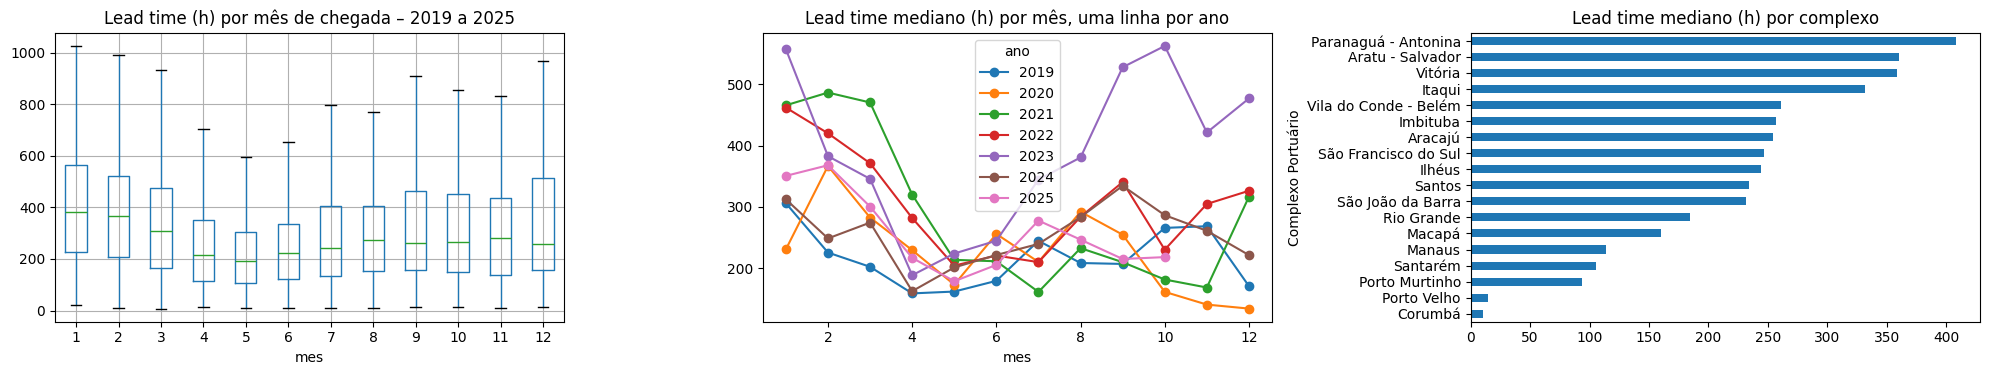

: 

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
Df_Dataset_Final.boxplot(column="lead_time_h", by="mes", ax=ax[0], showfliers=False)
ax[0].set_title("Lead time (h) por mês de chegada – 2019 a 2025")
(Df_Dataset_Final.pivot_table(index="mes", columns="ano", values="lead_time_h", aggfunc="median")
 .plot(ax=ax[1], marker="o"))
ax[1].set_title("Lead time mediano (h) por mês, uma linha por ano")
Df_Dataset_Final.groupby("Complexo Portuário")["lead_time_h"].median().sort_values().plot.barh(ax=ax[2])
ax[2].set_title("Lead time mediano (h) por complexo")
plt.suptitle("")
plt.tight_layout()
plt.show()